# nanoGPT | Team homework — **Member 1**

**Scope:** All 17 code-reading questions are answered in the companion Word file; this notebook runs **32 assigned experiments** for Member 1, not all 128 team runs.

**Fixed:** `block_size=64`, `n_layer=4`  
**Vary:** `n_head` 4/8 · `n_embd` 128/256 · `batch_size` 8/16 · `max_iters` 1000/2000 · `dropout` 0.1/0.2.

### Run instructions
1. In Colab choose **Runtime → Change runtime type → T4 GPU** (or another CUDA GPU).
2. Run cells 1–5, including the **preflight**. Do not run the 32 experiments until preflight says **PASSED**.
3. In the setup cell, `USE_DRIVE=True` is recommended so completed experiments survive Colab disconnects. Grant Google Drive access if asked.
4. Run the experiment cell (long training job). If it stops, start a new GPU session, rerun the setup cells, and run the experiment cell again; completed runs with intact checkpoints will be skipped.
5. Run the plots/export cells after some or all runs finish. Use actual outputs for the report; **do not present preflight results as a full experiment**.

**Notes:** This runs the official Karpathy nanoGPT implementation. The fresh `sample.py` is given a one-line PyTorch compatibility fix for loading *only checkpoints created by this notebook*. Training retains nanoGPT's internal seed 1337; `--seed` is deliberately **not** passed to `train.py`.

In [9]:
# 1 — Install dependency, clone/check repo, prepare Shakespeare data.
from pathlib import Path
import os, sys, subprocess, hashlib, json, time, re, itertools, threading, csv, shutil, traceback
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch

subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'tiktoken'], check=True)
repo = Path('/content/nanoGPT') if Path('/content').exists() else Path.cwd() / 'nanoGPT'
if not (repo / 'train.py').is_file():
    subprocess.run(['git', 'clone', '--depth', '1',
                    'https://github.com/karpathy/nanoGPT.git', str(repo)], check=True)
os.chdir(repo)
subprocess.run([sys.executable, 'data/shakespeare_char/prepare.py'], check=True)
commit_id = subprocess.check_output(['git', 'rev-parse', 'HEAD'], text=True).strip()
dataset_path = repo / 'data/shakespeare_char/input.txt'
dataset_sha256 = hashlib.sha256(dataset_path.read_bytes()).hexdigest()
print('nanoGPT commit:', commit_id)
print('Shakespeare SHA256:', dataset_sha256)
print('CUDA available:', torch.cuda.is_available())
if not torch.cuda.is_available():
    raise RuntimeError('No CUDA GPU detected: in Colab choose Runtime > Change runtime type > T4 GPU.')

# PyTorch 2.6+ defaults to weights_only=True in torch.load; the original
# nanoGPT sample.py expects to load its own complete checkpoint dict.
# Do not use weights_only=False for unknown/untrusted checkpoint files.
sample_py = repo / 'sample.py'
sample_src = sample_py.read_text(encoding='utf-8')
old = 'torch.load(ckpt_path, map_location=device)'
new = 'torch.load(ckpt_path, map_location=device, weights_only=False)'
if old in sample_src:
    sample_py.write_text(sample_src.replace(old, new, 1), encoding='utf-8')
    print('Applied local checkpoint compatibility fix in sample.py.')
elif new not in sample_src:
    raise RuntimeError('The sample.py checkpoint-loading line has changed. Inspect it before continuing.')

nanoGPT commit: 3adf61e154c3fe3fca428ad6bc3818b27a3b8291
Shakespeare SHA256: 86c4e6aa9db7c042ec79f339dcb96d42b0075e16b8fc2e86bf0ca57e2dc565ed
CUDA available: True


In [10]:
# 2 — Member 1 settings and persistent output directory.
USE_DRIVE = False  # Recommended: saves all logs, figures, checkpoints, samples to Drive.
if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    RESULTS = Path('/content/drive/MyDrive/nanoGPT_Member1_Results')
else:
    RESULTS = repo / 'nanoGPT_Member1_Results'  # NOT persistent after runtime reset!
RESULTS.mkdir(parents=True, exist_ok=True)

SEED = 1337  # train.py internally sets torch.manual_seed(1337) on one GPU.
FIXED = {'block_size': 64, 'n_layer': 4}
N_HEADS = (4, 8)
N_EMBDS = (128, 256)
BATCH_SIZES = (8, 16)
MAX_ITERS = (1000, 2000)
DROPOUTS = (0.1, 0.2)

configs=[]
for run_id, (heads, embd, batch, steps, drop) in enumerate(
    itertools.product(N_HEADS, N_EMBDS, BATCH_SIZES, MAX_ITERS, DROPOUTS), 1
):
    assert embd % heads == 0
    configs.append({
        'run_id':run_id, 'block_size':64, 'n_layer':4,
        'n_head':heads, 'n_embd':embd, 'batch_size':batch,
        'max_iters':steps, 'dropout':drop,
    })
assert len(configs)==32
pd.DataFrame(configs).to_csv(RESULTS/'member1_experiment_grid.csv', index=False)
(RESULTS/'provenance.json').write_text(json.dumps({
    'nanoGPT_commit':commit_id, 'dataset_sha256':dataset_sha256,
    'seed_in_train_py':1337, 'torch_version':torch.__version__,
    'assumptions':'single CUDA GPU; trained from scratch; no --seed config override',
}, indent=2, default=str), encoding='utf-8')
print('Member 1: 32 unique configurations.')
print('Result folder:',RESULTS)
display(pd.DataFrame(configs).head(8))

Member 1: 32 unique configurations.
Result folder: /content/nanoGPT/nanoGPT_Member1_Results


,run_id,block_size,n_layer,n_head,n_embd,batch_size,max_iters,dropout
0,1,64,4,4,128,8,1000,0.1
1,2,64,4,4,128,8,1000,0.2
2,3,64,4,4,128,8,2000,0.1
3,4,64,4,4,128,8,2000,0.2
4,5,64,4,4,128,16,1000,0.1
5,6,64,4,4,128,16,1000,0.2
6,7,64,4,4,128,16,2000,0.1
7,8,64,4,4,128,16,2000,0.2


In [11]:
# 3 — Train/sample helpers, log parsing, and observed GPU memory sampling.
EVAL_PATTERN = re.compile(r'step\s+(\d+):\s+train loss\s+([\d.]+),\s+val loss\s+([\d.]+)')


def gpu_total_used_mib():
    """GPU-wide memory used, sampled at intervals, not precise per-model peak."""
    try:
        p = subprocess.run(['nvidia-smi','--query-gpu=memory.used',
                            '--format=csv,noheader,nounits'], text=True,
                           capture_output=True, timeout=5, check=False)
        lines = [line.strip().split()[0] for line in p.stdout.splitlines() if line.strip()]
        return max(float(x) for x in lines) if lines else float('nan')
    except Exception:
        return float('nan')


def run_logged(command, log_path, monitor_gpu=False):
    """Stream important output to Colab while writing every output line to disk."""
    log_path=Path(log_path)
    log_path.parent.mkdir(parents=True, exist_ok=True)
    finished=threading.Event()
    observed=[]
    def monitor():
        while not finished.is_set():
            v = gpu_total_used_mib()
            if np.isfinite(v): observed.append(v)
            finished.wait(1.0)
    t = threading.Thread(target=monitor, daemon=True) if monitor_gpu else None
    if t: t.start()
    env=os.environ.copy()
    env['PYTHONUNBUFFERED']='1'
    proc=subprocess.Popen([str(x) for x in command], cwd=repo,
        stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
        text=True, bufsize=1, env=env)
    tail=[]
    try:
        with log_path.open('w',encoding='utf-8') as log:
            for line in proc.stdout:
                log.write(line)
                log.flush()
                tail.append(line.rstrip())
                if len(tail)>35: tail.pop(0)
                line_low=line.lower()
                if ('step ' in line_low or 'saving checkpoint' in line_low
                    or 'number of parameters' in line_low or 'error' in line_low
                    or 'traceback' in line_low or 'warning' in line_low):
                    print(line.rstrip())
        rc=proc.wait()
    finally:
        finished.set()
        if t: t.join(timeout=3)
    if rc != 0:
        raise RuntimeError('Training/sampling failed. See '+str(log_path)
                          +'\nLast lines:\n'+'\n'.join(tail[-18:]))
    return max(observed) if observed else float('nan')


def training_command(cfg, out, preflight=False):
    return [sys.executable,'train.py','config/train_shakespeare_char.py',
        '--device=cuda','--compile=False', '--init_from=scratch',
        '--gradient_accumulation_steps=1','--always_save_checkpoint=True',
        '--eval_interval='+str(1 if preflight else 200),
        '--eval_iters='+str(2 if preflight else 40),
        '--log_interval='+str(1 if preflight else 100),
        '--out_dir='+str(out),
        '--block_size='+str(cfg['block_size']),
        '--n_layer='+str(cfg['n_layer']),
        '--n_head='+str(cfg['n_head']),
        '--n_embd='+str(cfg['n_embd']),
        '--batch_size='+str(cfg['batch_size']),
        '--max_iters='+str(2 if preflight else cfg['max_iters']),
        '--lr_decay_iters='+str(2 if preflight else cfg['max_iters']),
        '--dropout='+str(cfg['dropout'])]


def sample_command(out):
    return [sys.executable,'sample.py','--out_dir='+str(out),
        '--device=cuda','--compile=False','--seed='+str(SEED),
        '--num_samples=1','--max_new_tokens=300',
        '--temperature=0.8','--top_k=20']


def eval_history(log_path):
    text=Path(log_path).read_text(encoding='utf-8')
    rows=[(int(it),float(train),float(val)) for it,train,val in EVAL_PATTERN.findall(text)]
    return pd.DataFrame(rows,columns=['iteration','train_loss','val_loss'])


def count_unique_parameters(ckpt_path):
    # Only open checkpoints generated by this notebook. Never unpickle unknown files.
    from model import GPT, GPTConfig
    ckpt = torch.load(ckpt_path, map_location='cpu', weights_only=False)
    net = GPT(GPTConfig(**ckpt['model_args']))
    result=sum(p.numel() for p in net.parameters())  # tied weights counted once
    del ckpt,net
    return int(result)


def plot_one(history, path, title):
    fig, ax=plt.subplots(figsize=(7.2,4))
    ax.plot(history.iteration,history.train_loss,marker='o',label='Training')
    ax.plot(history.iteration,history.val_loss,marker='o',label='Validation')
    ax.set(xlabel='Iteration',ylabel='Cross-entropy loss',title=title)
    ax.legend(); ax.grid(alpha=0.25)
    fig.tight_layout(); fig.savefig(path,dpi=170); plt.close(fig)

In [12]:
# 4 — Preflight: verify both training and sampling before committing to 32 runs.
preflight_dir=RESULTS/'_preflight'
preflight_dir.mkdir(parents=True,exist_ok=True)
print('Preflight: 2 short training iterations (NOT an assignment result).')
run_logged(training_command(configs[0], preflight_dir, preflight=True),
           preflight_dir/'training.log',monitor_gpu=True)
preflight_ckpt=preflight_dir/'ckpt.pt'
if not preflight_ckpt.exists():
    raise RuntimeError('Preflight checkpoint not found; inspect _preflight/training.log.')
run_logged(sample_command(preflight_dir),preflight_dir/'sample.log')
print('PREFLIGHT PASSED: checkpoint saved and sample.py generated text.')
print('Sample preview (last 600 characters):')
print((preflight_dir/'sample.log').read_text(encoding='utf-8')[-600:])

Preflight: 2 short training iterations (NOT an assignment result).
number of parameters: 0.80M
/content/nanoGPT/train.py:196: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
step 0: train loss 4.1698, val loss 4.1658
step 1: train loss 4.1436, val loss 4.1569
saving checkpoint to /content/nanoGPT/nanoGPT_Member1_Results/_preflight
step 2: train loss 4.1082, val loss 4.1367
saving checkpoint to /content/nanoGPT/nanoGPT_Member1_Results/_preflight
number of parameters: 0.80M
PREFLIGHT PASSED: checkpoint saved and sample.py generated text.
Sample preview (last 600 characters):
preflight
Overriding: device = cuda
Overriding: compile = False
Overriding: seed = 1337
Overriding: num_samples = 1
Overriding: max_new_tokens = 300
Overriding: temperature = 0.8
Overriding: top_k = 20
number of parameters: 0.80M
Loading meta from data/shakespeare_char/meta.pkl...

?3f;$LDkRZkNdlO'i,ZO'isrF,yCt!Ebai3eYNMBkzbd!:QQrGBGY33m?G

In [13]:
# 5 — Run / resume the 32 required experiments.
# This is a long GPU job. Save to Google Drive and return after it completes.
SUMMARY_FILE=RESULTS/'experiment_summary.csv'
if SUMMARY_FILE.exists():
    summary=pd.read_csv(SUMMARY_FILE)
    records={int(r['run_id']):r for r in summary.to_dict('records')}
else:
    records={}


def save_summary():
    rows=[records[k] for k in sorted(records)]
    pd.DataFrame(rows).to_csv(SUMMARY_FILE,index=False)

for cfg in configs:
    i=cfg['run_id']
    run_dir=RESULTS/f'run_{i:02d}'
    ckpt_dir=run_dir/'checkpoint'
    ckpt=ckpt_dir/'ckpt.pt'
    if i in records and records[i].get('status')=='complete' and ckpt.is_file():
        print(f'Run {i:02d}/32: already complete, skipping.')
        continue
    run_dir.mkdir(parents=True,exist_ok=True)
    ckpt_dir.mkdir(parents=True,exist_ok=True)
    (run_dir/'config.json').write_text(json.dumps(cfg,indent=2),encoding='utf-8')
    command=training_command(cfg,ckpt_dir)
    (run_dir/'command.txt').write_text(' '.join(command),encoding='utf-8')
    print(f'\nRUN {i:02d}/32 | heads={cfg["n_head"]}, embd={cfg["n_embd"]}, '
          f'batch={cfg["batch_size"]}, iterations={cfg["max_iters"]}, dropout={cfg["dropout"]}')
    t0=time.perf_counter()
    try:
        observed_gpu_mib=run_logged(command,run_dir/'training.log',monitor_gpu=True)
        elapsed=time.perf_counter()-t0
        if not ckpt.is_file():
            raise RuntimeError(f'Run {i}: checkpoint missing. See {run_dir/"training.log"}')
        history=eval_history(run_dir/'training.log')
        if history.empty:
            raise RuntimeError(f'Run {i}: no evaluation metrics parsed.')
        history.to_csv(run_dir/'loss_history.csv',index=False)
        plot_one(history,run_dir/'loss_curve.png',f'Run {i:02d}: training versus validation')
        # Sampling failures are real failures: don't silently mark run complete.
        run_logged(sample_command(ckpt_dir),run_dir/'sample.txt',monitor_gpu=False)
        last=history.iloc[-1]
        record={**cfg, 'status':'complete',
            'final_train_loss':float(last.train_loss),
            'final_val_loss':float(last.val_loss),
            'best_val_loss':float(history.val_loss.min()),
            'loss_gap':float(last.val_loss-last.train_loss),
            'wall_seconds':round(elapsed,2),
            'parameter_count':count_unique_parameters(ckpt),
            'gpu_used_mib_sampled_peak':observed_gpu_mib,
            'training_tokens_approx':cfg['block_size']*cfg['batch_size']*(cfg['max_iters']+1),
            'run_folder':str(run_dir),
        }
        records[i]=record
        save_summary()
        print(f'Completed {i:02d}/32; val={record["final_val_loss"]:.4f}, '
              f'time={elapsed/60:.1f} min')
    except Exception as exc:
        records[i]={**cfg,'status':'failed','error':str(exc),'run_folder':str(run_dir)}
        save_summary()
        raise RuntimeError(f'STOPPED on run {i:02d}; see {run_dir}/training.log '
                           'or sample.txt. Fix the error, then rerun this cell. '
                           'Already completed runs will be skipped.') from exc

print('ALL 32 MEMBER 1 EXPERIMENTS COMPLETED.')


RUN 01/32 | heads=4, embd=128, batch=8, iterations=1000, dropout=0.1
number of parameters: 0.80M
/content/nanoGPT/train.py:196: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
step 0: train loss 4.1670, val loss 4.1671
step 200: train loss 2.5417, val loss 2.5507
saving checkpoint to /content/nanoGPT/nanoGPT_Member1_Results/run_01/checkpoint
step 400: train loss 2.4421, val loss 2.4487
saving checkpoint to /content/nanoGPT/nanoGPT_Member1_Results/run_01/checkpoint
step 600: train loss 2.3797, val loss 2.3867
saving checkpoint to /content/nanoGPT/nanoGPT_Member1_Results/run_01/checkpoint
step 800: train loss 2.3095, val loss 2.3357
saving checkpoint to /content/nanoGPT/nanoGPT_Member1_Results/run_01/checkpoint
step 1000: train loss 2.2839, val loss 2.2963
saving checkpoint to /content/nanoGPT/nanoGPT_Member1_Results/run_01/checkpoint
number of parameters: 0.80M
number of parameters: 0.80M
Completed 01/32; va

Completed: 32/32. Best observed configuration:


,run_id,block_size,n_layer,n_head,n_embd,batch_size,max_iters,dropout,status,final_train_loss,final_val_loss,best_val_loss,loss_gap,wall_seconds,parameter_count,gpu_used_mib_sampled_peak,training_tokens_approx,run_folder
0,15,64,4,4,256,16,2000,0.1,complete,1.5866,1.7373,1.7373,0.1507,35.98,3181056,265.0,2049024,/content/nanoGPT/nanoGPT_Member1_Results/run_15
1,31,64,4,8,256,16,2000,0.1,complete,1.5844,1.7379,1.7379,0.1535,37.42,3181056,279.0,2049024,/content/nanoGPT/nanoGPT_Member1_Results/run_31
2,32,64,4,8,256,16,2000,0.2,complete,1.6617,1.8150,1.8150,0.1533,37.21,3181056,279.0,2049024,/content/nanoGPT/nanoGPT_Member1_Results/run_32
3,16,64,4,4,256,16,2000,0.2,complete,1.6759,1.8306,1.8306,0.1547,35.86,3181056,265.0,2049024,/content/nanoGPT/nanoGPT_Member1_Results/run_16
4,11,64,4,4,256,8,2000,0.1,complete,1.7296,1.8779,1.8779,0.1483,36.14,3181056,233.0,1024512,/content/nanoGPT/nanoGPT_Member1_Results/run_11
5,27,64,4,8,256,8,2000,0.1,complete,1.7273,1.8945,1.8904,0.1672,35.71,3181056,237.0,1024512,/content/nanoGPT/nanoGPT_Member1_Results/run_27
6,13,64,4,4,256,16,1000,0.1,complete,1.7803,1.9145,1.9145,0.1342,21.16,3181056,265.0,1025024,/content/nanoGPT/nanoGPT_Member1_Results/run_13
7,29,64,4,8,256,16,1000,0.1,complete,1.8004,1.9249,1.9249,0.1245,21.40,3181056,279.0,1025024,/content/nanoGPT/nanoGPT_Member1_Results/run_29
8,28,64,4,8,256,8,2000,0.2,complete,1.8215,1.9489,1.9470,0.1274,35.12,3181056,237.0,1024512,/content/nanoGPT/nanoGPT_Member1_Results/run_28
9,12,64,4,4,256,8,2000,0.2,complete,1.8299,1.9515,1.9515,0.1216,36.53,3181056,233.0,1024512,/content/nanoGPT/nanoGPT_Member1_Results/run_12


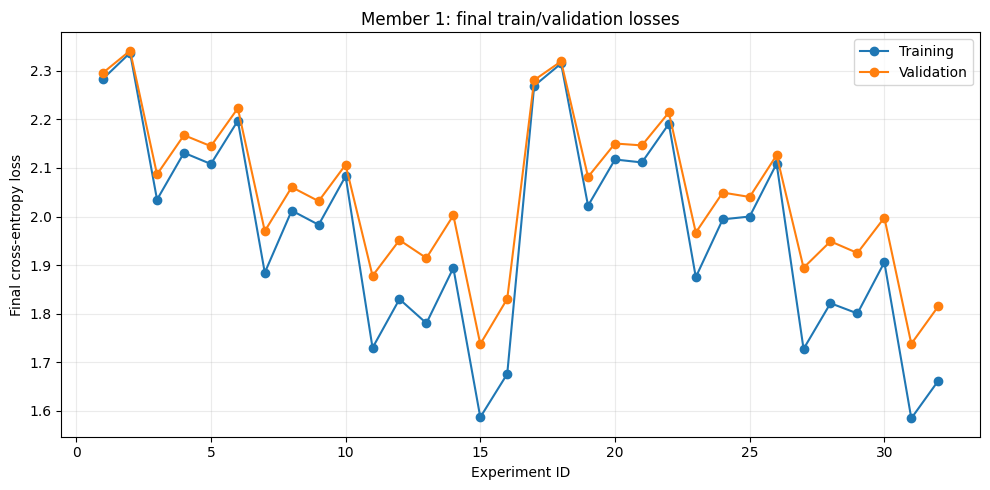

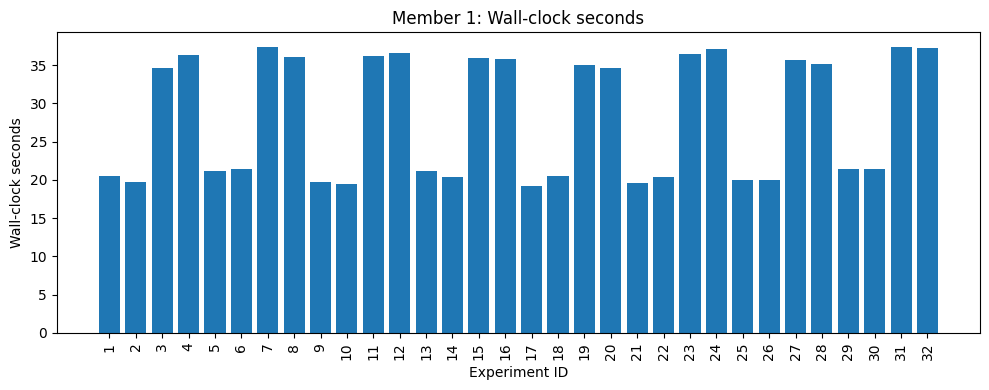

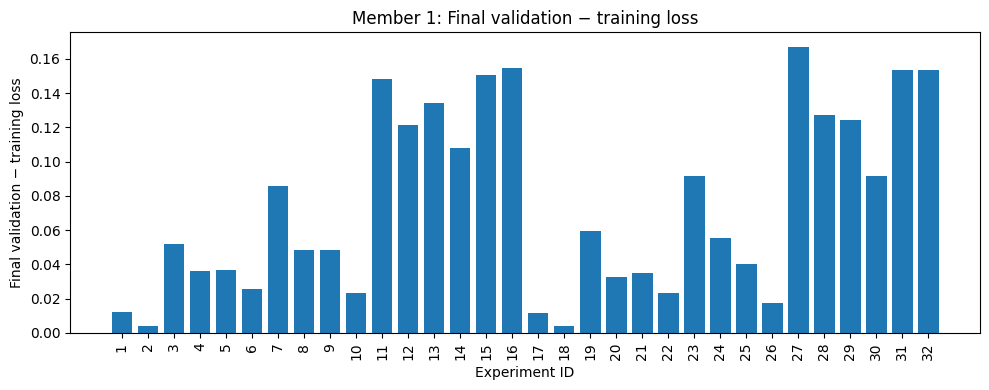

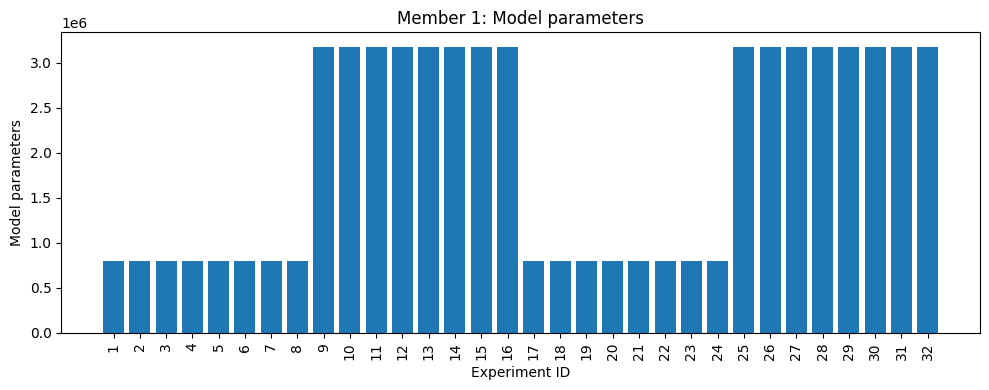

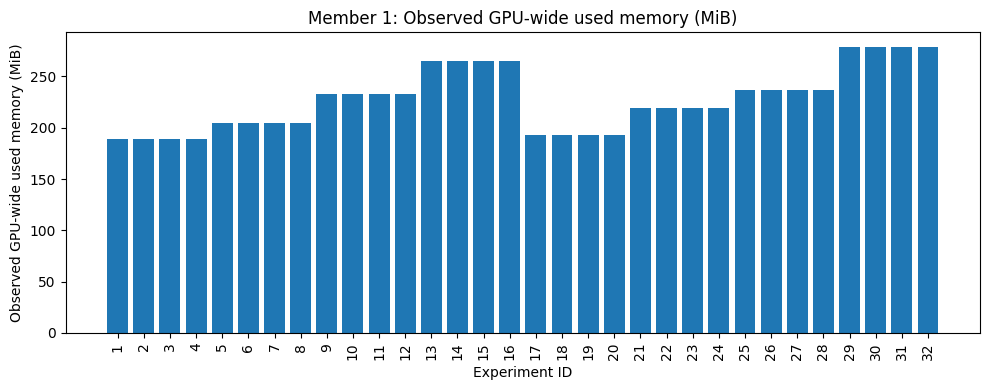

In [14]:
# 6 — Ranked results + summary plots (can run on partial completion too).
summary=pd.read_csv(RESULTS/'experiment_summary.csv')
completed=summary.loc[summary.status=='complete'].copy()
if completed.empty:
    raise RuntimeError('No completed experiments yet. Run the preflight and experiments first.')
ranked=completed.sort_values(['best_val_loss','wall_seconds']).reset_index(drop=True)
ranked.to_csv(RESULTS/'ranked_experiments.csv',index=False)
print(f'Completed: {len(completed)}/32. Best observed configuration:')
display(ranked.head(10))

fig,ax=plt.subplots(figsize=(10,5))
x=completed.sort_values('run_id')
ax.plot(x.run_id,x.final_train_loss,marker='o',label='Training')
ax.plot(x.run_id,x.final_val_loss,marker='o',label='Validation')
ax.set(xlabel='Experiment ID',ylabel='Final cross-entropy loss',
       title='Member 1: final train/validation losses')
ax.legend();ax.grid(alpha=0.25);fig.tight_layout()
fig.savefig(RESULTS/'comparison_final_losses.png',dpi=180);plt.show()

for column, ylabel, filename in [
    ('wall_seconds','Wall-clock seconds','comparison_training_time.png'),
    ('loss_gap','Final validation − training loss','comparison_loss_gap.png'),
    ('parameter_count','Model parameters','comparison_parameter_count.png'),
    ('gpu_used_mib_sampled_peak','Observed GPU-wide used memory (MiB)','comparison_gpu_memory.png'),
]:
    fig,ax=plt.subplots(figsize=(10,4))
    ax.bar(x.run_id.astype(str),x[column])
    ax.set(xlabel='Experiment ID',ylabel=ylabel,title='Member 1: '+ylabel)
    ax.tick_params(axis='x',labelrotation=90)
    fig.tight_layout();fig.savefig(RESULTS/filename,dpi=180);plt.show()

In [15]:
# 7 — Balanced factorial comparisons and report-friendly export.
metrics=['final_train_loss','final_val_loss','best_val_loss',
         'loss_gap','wall_seconds','parameter_count']
frames=[]
for hp in ('n_head','n_embd','batch_size','max_iters','dropout'):
    effect=completed.groupby(hp,dropna=False)[metrics].mean().reset_index()
    effect.insert(0,'hyperparameter',hp)
    effect=effect.rename(columns={hp:'value'})
    frames.append(effect)
effects=pd.concat(frames,ignore_index=True)
effects.to_csv(RESULTS/'hyperparameter_effects.csv',index=False)
print('Hyperparameter averages (interpret with care if fewer than all 32 runs are complete):')
display(effects)

best_dir=Path(ranked.iloc[0].run_folder)
print('Best validation model:',best_dir)
print('Generated sample excerpt:')
print((best_dir/'sample.txt').read_text(encoding='utf-8')[-900:])

Hyperparameter averages (interpret with care if fewer than all 32 runs are complete):


,hyperparameter,value,final_train_loss,final_val_loss,best_val_loss,loss_gap,wall_seconds,parameter_count
0,n_head,4.0,1.972000,2.046450,2.046450,0.074450,28.262500,1992576.0
1,n_head,8.0,1.969113,2.043456,2.043081,0.074344,28.206250,1992576.0
2,n_embd,128.0,2.117825,2.156269,2.156269,0.038444,28.121250,804096.0
3,n_embd,256.0,1.823287,1.933637,1.933262,0.110350,28.347500,3181056.0
4,batch_size,8.0,2.049669,2.106412,2.106037,0.056744,27.691250,1992576.0
5,batch_size,16.0,1.891444,1.983494,1.983494,0.092050,28.777500,1992576.0
6,max_iters,1000.0,2.085562,2.131975,2.131975,0.046412,20.380000,1992576.0
7,max_iters,2000.0,1.855550,1.957931,1.957556,0.102381,36.088750,1992576.0
8,dropout,0.1,1.923806,2.008319,2.008062,0.084512,28.208125,1992576.0
9,dropout,0.2,2.017306,2.081587,2.081469,0.064281,28.260625,1992576.0


Best validation model: /content/nanoGPT/nanoGPT_Member1_Results/run_15
Generated sample excerpt:
Overriding: out_dir = /content/nanoGPT/nanoGPT_Member1_Results/run_15/checkpoint
Overriding: device = cuda
Overriding: compile = False
Overriding: seed = 1337
Overriding: num_samples = 1
Overriding: max_new_tokens = 300
Overriding: temperature = 0.8
Overriding: top_k = 20
number of parameters: 3.16M
Loading meta from data/shakespeare_char/meta.pkl...


Clown:
Reak cown, which you that senature to take and my day;
And be that foul him to becoment oates with my fears
appy on my to them of it heart my follow,
We miseech not will it the overs, and the news in was theirs no mean.

AUTOLYCUS:
Now up the speak you lord.
I can peak a down my liked mother
---------------



In [16]:
# 8 — Make a compact ZIP of submission-ready evidence (without large .pt weights).
# Checkpoints remain in RESULTS / run_XX / checkpoint and need not be uploaded to GitHub.
import zipfile
archive=RESULTS/'Member1_report_evidence.zip'
with zipfile.ZipFile(archive,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for path in RESULTS.rglob('*'):
        if not path.is_file() or path==archive:
            continue
        if path.suffix in {'.pt','.tmp'}:  # skip model checkpoints / temporary files
            continue
        if path.name=='sample.log' and '_preflight' in path.parts: continue
        z.write(path,path.relative_to(RESULTS))
print('Created:',archive)
print('Files for report: experiment_summary.csv, ranked_experiments.csv, '
      'hyperparameter_effects.csv, comparison charts, individual loss plots, '
      'samples, commands and logs.')

Created: /content/nanoGPT/nanoGPT_Member1_Results/Member1_report_evidence.zip
Files for report: experiment_summary.csv, ranked_experiments.csv, hyperparameter_effects.csv, comparison charts, individual loss plots, samples, commands and logs.


In [17]:
from google.colab import files

files.download(str(archive))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### How these experiments should be interpreted
- All 32 Member 1 configurations use the **same 90/10 Shakespeare train/validation split** created by `prepare.py`, the same internal training seed, and the same evaluation settings.
- Batch size and `max_iters` intentionally vary according to the assignment. Their configurations see **different numbers of training tokens**, so do not say they were compared at equal compute budgets.
- `lr_decay_iters` is set equal to each run's `max_iters`, as in the recommended Shakespeare training configuration; `warmup_iters` stays at the repository's Shakespeare setting.
- Training and validation curves use **evaluation** losses (averaged over 40 randomly sampled batches each); they are not the per-step training loss.
- GPU memory is **sampled total GPU used memory**, not a guaranteed exact per-process peak. Mention this limitation in the report.
- Run the 32 experiments before writing Results, Analysis, and Conclusion. The `_preflight` test is only a compatibility test.
- The `sample.py` loading fix uses `weights_only=False` only for the models the notebook itself trained. Never load an untrusted checkpoint that way.